# Exploratory Data Analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statistics import NormalDist

## Setup

In [2]:
pd.set_option("display.precision", 2)
pd.set_option("display.width", 140)

LEVELS = [1, 2, 3, 4]
LEVEL_COLORS = {1: "#86b6ef", 2: "#3987e5", 3: "#1c5cab", 4: "#0d366b"}
LEVEL_NAMES = {1: "1 low", 2: "2 moderate", 3: "3 considerable", 4: "4 high"}
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": GREY, "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.titleweight": "bold", "axes.titlesize": 11,
})

data = pd.read_csv("data/final.csv", parse_dates=["date"])
data = data.sort_values(["region", "date"]).reset_index(drop=True)

NUM = {
    "air_temp_mean": "Mean air temp (°C)", "air_temp_min": "Min air temp (°C)",
    "air_temp_max": "Max air temp (°C)", "wind_speed_mean": "Mean wind (m/s)",
    "wind_gust_max": "Max gust (m/s)", "rel_humidity_mean": "Rel. humidity (%)",
    "pressure_mean": "Station pressure (hPa)", "sunshine_sum": "Sunshine (h)",
    "snow_depth_cm": "Snow depth (cm)", "precip_sum_mm": "Precipitation (mm)",
}

### Feature engineering

| Column | Definition | Used in |
|---|---|---|
| `month` | calendar month of `date` | 3.1, 4.1, 4.2 |
| `spring` | `True` for March–May (wet-snow period) | 4.2 |
| `prev_danger` | danger level of the **previous day** in the same region and season (NaN on the first day of a season) | 3.1, 4.5 |
| `snow_depth_clean` | snow depth after a causal 3-day rolling median (removes one-day sensor spikes, uses only past values); helper for the snow changes | 4.5 |
| `precip_3d`, `precip_7d` | precipitation summed over the last 3 / 7 days | 4.5 |
| `log_precip_3d` | $\log(1 + \text{precip\_3d})$, log transformation against the strong right skew (DEA-06) | 4.5 |
| `snow_change_3d`, `snow_change_14d` | change of `snow_depth_clean` over the last 3 / 14 days (fresh snow vs. settling) | 4.5 |
| `temp_mean_14d` | mean air temperature over the last 14 days (long cold spells) | 4.5 |
| `pressure_anom` | pressure minus the station's mean pressure (removes the elevation effect, 2.5) | 4.5 |
| `snow_depth_z` | snow depth standardised per station, $(x - \bar{x}_{station}) / s_{station}$ (DEA-06 standardization) | 4.5 |

- All rolling/lag features are computed per **(region, season)**, so no window reaches across the summer gap between two winters.
- Features that did **not** improve on the raw variables and were therefore dropped: 3-day max gust, 3-day mean temperature, daily temperature range, wind direction as sin/cos, day of season.

In [3]:
data["month"] = data["date"].dt.month
data["spring"] = data["month"].isin([3, 4, 5])
grp = data.groupby(["region", "season"])            # per season: no window reaches over the summer gap
data["prev_danger"] = grp["danger_max"].shift(1)

# snow depth
data["snow_depth_clean"] = grp["snow_depth_cm"].transform(lambda x: x.rolling(3, min_periods=1).median())
data["snow_change_3d"] = data.groupby(["region", "season"])["snow_depth_clean"].diff(3)
data["snow_change_14d"] = data.groupby(["region", "season"])["snow_depth_clean"].diff(14)

# precipitation accumulated over several days
data["precip_3d"] = grp["precip_sum_mm"].transform(lambda x: x.rolling(3, min_periods=1).sum())
data["precip_7d"] = grp["precip_sum_mm"].transform(lambda x: x.rolling(7, min_periods=1).sum())
data["log_precip_3d"] = np.log1p(data["precip_3d"])

# long-term temp
data["temp_mean_14d"] = grp["air_temp_mean"].transform(lambda x: x.rolling(14, min_periods=1).mean())

# per-station normalisation
st = data.groupby("station_name")
data["pressure_anom"] = data["pressure_mean"] - st["pressure_mean"].transform("mean")
data["snow_depth_z"] = (data["snow_depth_cm"] - st["snow_depth_cm"].transform("mean")) / st["snow_depth_cm"].transform("std")

ENGINEERED = ["month", "spring", "prev_danger", "snow_depth_clean", "snow_change_3d",
              "snow_change_14d", "precip_3d", "precip_7d", "log_precip_3d", "temp_mean_14d",
              "pressure_anom", "snow_depth_z"]

# numerical engineered features
ENG_NUM = {"log_precip_3d": "precip_sum_mm", "precip_3d": "precip_sum_mm", "precip_7d": "precip_sum_mm",
           "snow_change_14d": "snow_depth_cm", "snow_change_3d": "snow_depth_cm", "temp_mean_14d": "air_temp_mean",
           "snow_depth_z": "snow_depth_cm", "pressure_anom": "pressure_mean"}

print("missing values:", data[ENGINEERED].isna().sum()[lambda x: x > 0].to_dict(), "(first days of each season)")
data[["date", "region", "danger_max"] + ENGINEERED].head()

missing values: {'prev_danger': 63, 'snow_change_3d': 189, 'snow_change_14d': 882} (first days of each season)


,date,region,danger_max,month,spring,prev_danger,snow_depth_clean,snow_change_3d,snow_change_14d,precip_3d,precip_7d,log_precip_3d,temp_mean_14d,pressure_anom,snow_depth_z
0,2019-11-16,AT-07-07,2,11,False,NaN,33.06,NaN,NaN,6.15,6.15,1.97,-3.48,-13.54,-2.44
1,2019-11-17,AT-07-07,2,11,False,2.0,38.35,NaN,NaN,13.29,13.29,2.66,-4.34,-9.58,-2.23
2,2019-11-18,AT-07-07,2,11,False,2.0,43.64,NaN,NaN,24.32,24.32,3.23,-4.75,-8.79,-1.94
3,2019-11-19,AT-07-07,2,11,False,2.0,54.68,21.62,NaN,20.93,27.08,3.09,-5.12,-9.28,-2.00
4,2019-11-20,AT-07-07,2,11,False,2.0,54.68,16.33,NaN,13.79,27.08,2.69,-5.15,-2.67,-2.11


## 1. Univariate non-graphical EDA

### 1.1 Spread

In [4]:
def sample_var(x):
    x = x.dropna()
    return ((x - x.mean()) ** 2).sum() / (len(x) - 1)

spread = pd.DataFrame({
    "min": data[list(NUM)].min(), "max": data[list(NUM)].max(),
    "range": data[list(NUM)].max() - data[list(NUM)].min(),
    "variance (n-1)": {c: sample_var(data[c]) for c in NUM},
    "std": {c: np.sqrt(sample_var(data[c])) for c in NUM},
    "Q1": data[list(NUM)].quantile(0.25), "Q3": data[list(NUM)].quantile(0.75),
})
spread["IQR"] = spread["Q3"] - spread["Q1"]
spread

,min,max,range,variance (n-1),std,Q1,Q3,IQR
air_temp_mean,-20.80,15.12,35.91,25.08,5.01,-6.03,0.73,6.76
air_temp_min,-22.86,13.10,35.96,25.62,5.06,-8.87,-1.98,6.89
air_temp_max,-18.22,21.41,39.63,30.38,5.51,-2.46,4.77,7.22
wind_speed_mean,0.39,18.28,17.89,3.78,1.95,1.63,3.74,2.11
wind_gust_max,2.57,39.54,36.97,26.89,5.19,7.41,13.99,6.58
rel_humidity_mean,9.67,99.52,89.85,294.00,17.15,57.50,81.89,24.39
pressure_mean,680.71,866.34,185.63,1522.84,39.02,779.25,820.35,41.10
sunshine_sum,0.00,13.53,13.53,9.67,3.11,0.61,5.82,5.21
snow_depth_cm,0.00,318.74,318.74,4578.55,67.66,45.60,147.12,101.51
precip_sum_mm,0.00,70.10,70.10,21.10,4.59,0.00,1.59,1.59


In [5]:
rows = []
for c in NUM:
    x = data[c]
    lo, hi = x.quantile([0.005, 0.995]) # 0,5 % and 99,5 % quantile
    x_cut = x[x.between(lo, hi)]
    rows.append({"variable": c,
                 "range: all": x.max() - x.min(), "range: w/o 1%": x_cut.max() - x_cut.min(),
                 "std: all": x.std(), "std: w/o 1%": x_cut.std(),
                 "IQR: all": x.quantile(.75) - x.quantile(.25), "IQR: w/o 1%": x_cut.quantile(.75) - x_cut.quantile(.25),
                 "median: all": x.median(), "median: w/o 1%": x_cut.median()})
robust = pd.DataFrame(rows).set_index("variable")
for m in ["range", "std", "IQR", "median"]:
    robust[f"{m} change %"] = (robust[f"{m}: w/o 1%"] / robust[f"{m}: all"] - 1) * 100
robust[[c for c in robust if "change" in c]].round(1)

,range change %,std change %,IQR change %,median change %
variable,,,,
air_temp_mean,-29.4,-3.6,-1.3,0.0
air_temp_min,-29.0,-3.6,-1.1,0.0
air_temp_max,-28.4,-3.8,-1.3,0.0
wind_speed_mean,-43.0,-6.8,-1.4,0.0
wind_gust_max,-29.8,-4.6,-0.9,0.0
rel_humidity_mean,-16.0,-2.5,-1.0,0.0
pressure_mean,-9.4,-2.2,-0.9,0.0
sunshine_sum,-12.2,-1.9,-0.7,-1.1
snow_depth_cm,-12.2,-1.9,-0.8,-0.4


* Removing just 1% of the observations shrinks the **range** by 10–60%, and the **std** of precipitation drops by 18%. The **IQR** changes by at most 3.2%
* Precipitation has an IQR of only ~1.6 mm but a range of 70 mm, and its std is about three times its IQR ->  skewed with a long tail.

**Consequences:**
- Because of the skeweness we are going to use tree-based models.

### 1.3 Outliers

In [6]:
def outlier_counts(x):
    z = (x - x.mean()) / x.std()
    q1, q3 = x.quantile([0.25, 0.75]); iqr = q3 - q1
    mad = (x - x.median()).abs().median()
    return {"z-score |z|>3": (z.abs() > 3).sum(),
            "IQR fences": ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum(),
            "MAD > 3": ((x - x.median()).abs() / (1.4826 * mad) > 3).sum() if mad > 0 else np.nan,
            "MAD": mad}

out = pd.DataFrame({c: outlier_counts(data[c]) for c in NUM}).T
out["IQR fences %"] = out["IQR fences"] / len(data) * 100
out.sort_values("IQR fences", ascending=False)

,z-score |z|>3,IQR fences,MAD > 3,MAD,IQR fences %
precip_sum_mm,220.0,1409.0,4568.0,9.18e-03,14.48
pressure_mean,0.0,1041.0,769.0,2.05e+01,10.70
wind_speed_mean,172.0,481.0,598.0,9.27e-01,4.94
wind_gust_max,130.0,271.0,272.0,3.10e+00,2.79
air_temp_max,26.0,86.0,36.0,3.62e+00,0.88
air_temp_mean,22.0,75.0,26.0,3.35e+00,0.77
air_temp_min,22.0,65.0,26.0,3.43e+00,0.67
rel_humidity_mean,16.0,42.0,23.0,1.19e+01,0.43
snow_depth_cm,7.0,12.0,4.0,4.97e+01,0.12
sunshine_sum,11.0,0.0,0.0,2.52e+00,0.00


* The rules disagree strongly for skewed variables. For precipitation, the IQR rule flags 14.5% of all days because Q1 = 0, and since MAD ≈ 0.01 mm (about half the days are dry) the MAD rule flags almost half of the data, which is clearly useless.
* For pressure, the IQR rule flags ~11% of the rows, which are simply the days of the highest station (Pitztaler Gletscher), not unusual weather.
* The flagged precipitation days have clearly **higher** danger levels than the rest (65% level 3–4 vs. 30%), so they are the most informative observations, not errors.
* For temperatures, very few points (< 1%) are flagged by any rule.

**Consequences:**
-> we do **not** remove statistical outliers.

## 2. Univariate graphical EDA
### 2.1 Bar charts (categorical variables)

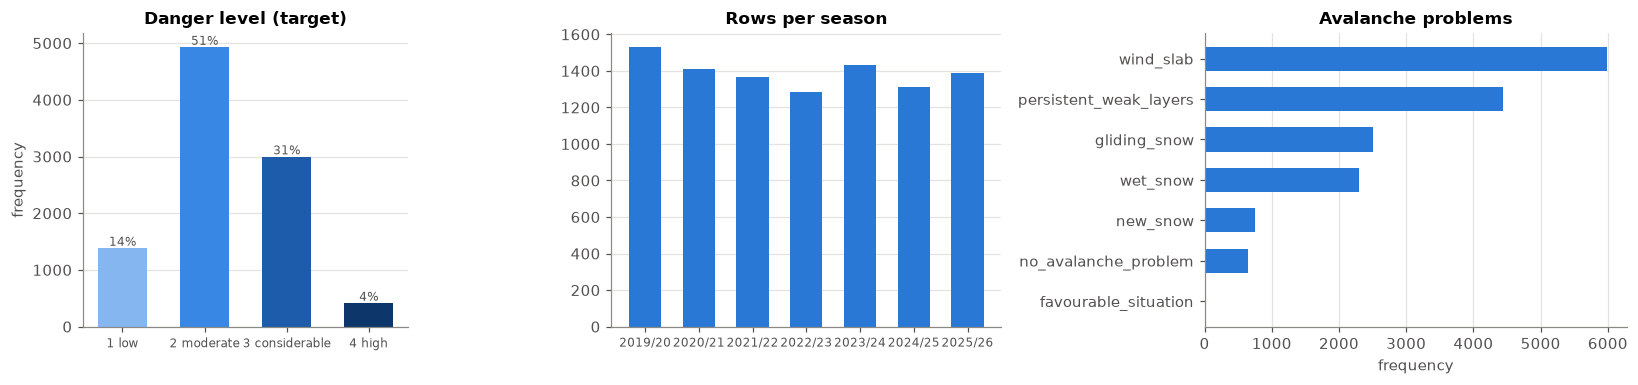

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1, 1.2, 1.3]})

t = data["danger_max"].value_counts().sort_index()
axes[0].bar([LEVEL_NAMES[l] for l in t.index], t.values, color=[LEVEL_COLORS[l] for l in t.index], width=0.6)
for i, v in enumerate(t.values):
    axes[0].text(i, v + 40, f"{v / t.sum():.0%}", ha="center", fontsize=8, color="#52514e")
axes[0].set_title("Danger level (target)"); axes[0].set_ylabel("frequency")
axes[0].tick_params(axis="x", labelsize=8)

season_mean = data.groupby("season").size()
axes[1].bar(season_mean.index, season_mean.values, color=BLUE, width=0.6)
axes[1].set_title("Rows per season"); axes[1].tick_params(axis="x", labelsize=8)

prob = data["problems"].str.split(";").explode().value_counts()
axes[2].barh(prob.index, prob.values, color=BLUE, height=0.6)
axes[2].invert_yaxis(); axes[2].set_title("Avalanche problems"); axes[2].set_xlabel("frequency")
for ax in axes[:2]:
    ax.grid(axis="x", visible=False)
axes[2].grid(axis="y", visible=False)
plt.tight_layout()

**Consequences:** the model will be trained on an imbalanced target. Always predicting level 2 already gives ~51% accuracy.

### 2.2 Histograms: bin width matters


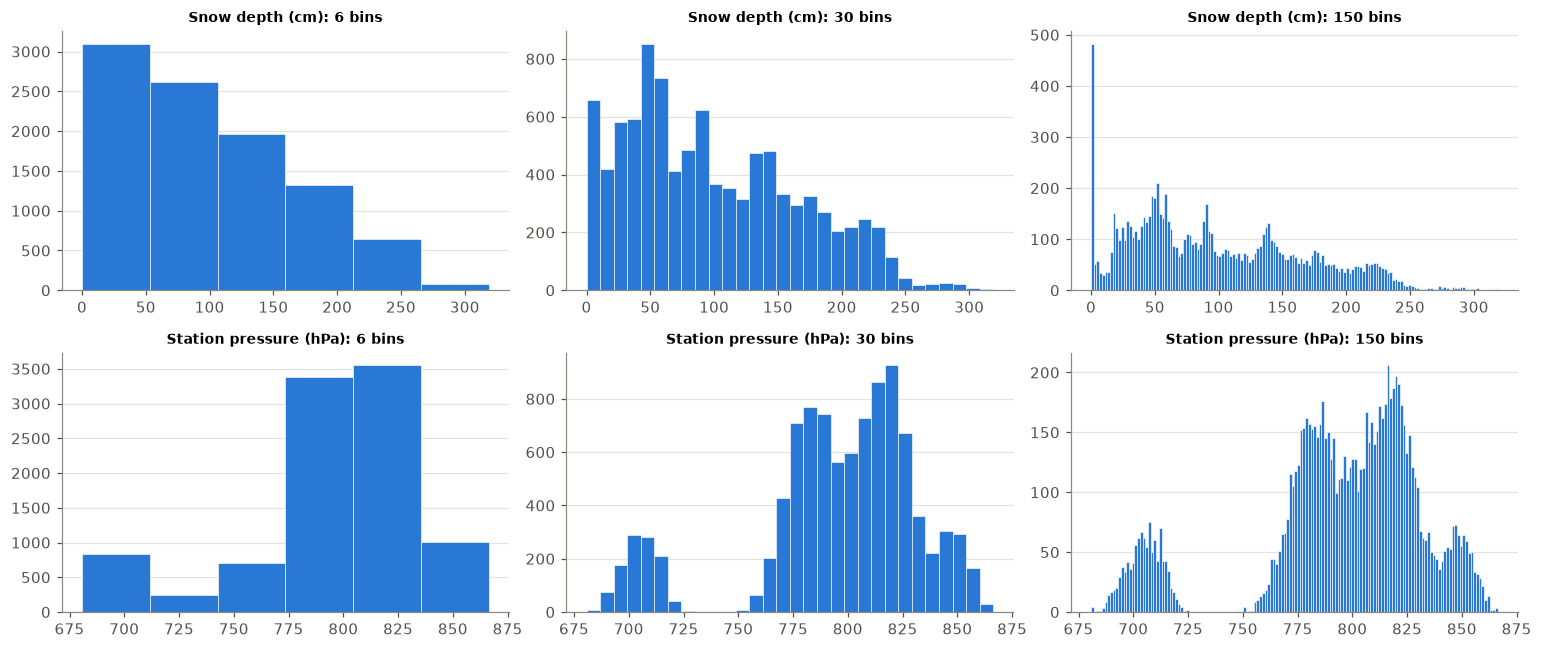

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for row, col in enumerate(["snow_depth_cm", "pressure_mean"]):
    for ax, bins in zip(axes[row], [6, 30, 150]):
        ax.hist(data[col], bins=bins, color=BLUE, edgecolor="white", linewidth=0.4)
        ax.set_title(f"{NUM[col]}: {bins} bins", fontsize=9)
        ax.grid(axis="x", visible=False)
plt.tight_layout()

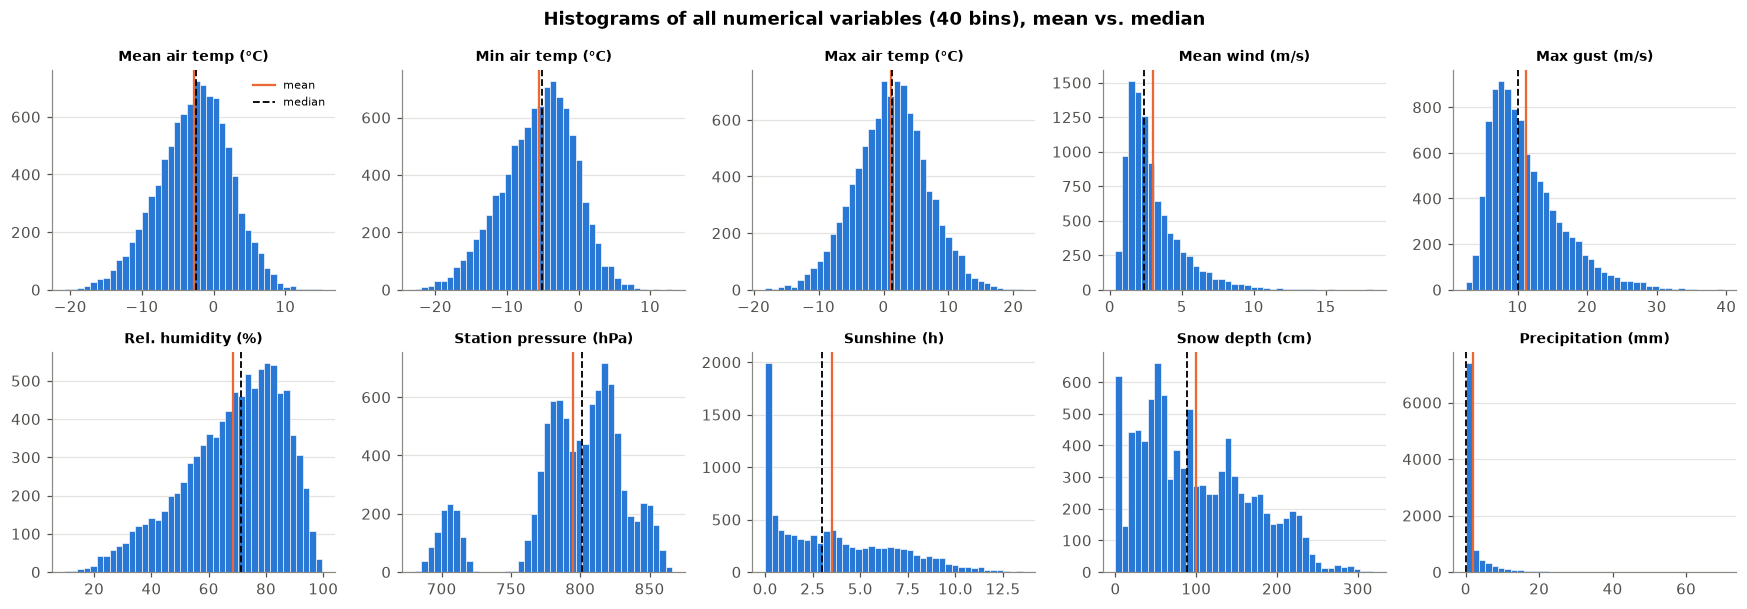

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(16, 5.6))
for ax, (col, label) in zip(axes.flat, NUM.items()):
    ax.hist(data[col], bins=40, color=BLUE, edgecolor="white", linewidth=0.4)
    ax.axvline(data[col].mean(), color=ORANGE, lw=1.5, label="mean")
    ax.axvline(data[col].median(), color="black", lw=1.2, ls="--", label="median")
    ax.set_title(label, fontsize=9); ax.grid(axis="x", visible=False)
axes[0, 0].legend(fontsize=7, frameon=False)
fig.suptitle("Histograms of all numerical variables (40 bins), mean vs. median", fontweight="bold")
plt.tight_layout()

- the mean lies to the right of the median for precipitation, wind, gusts and snow depth (right skew),
- and to the left for humidity and pressure (left skew)

### 2.4 Boxplots

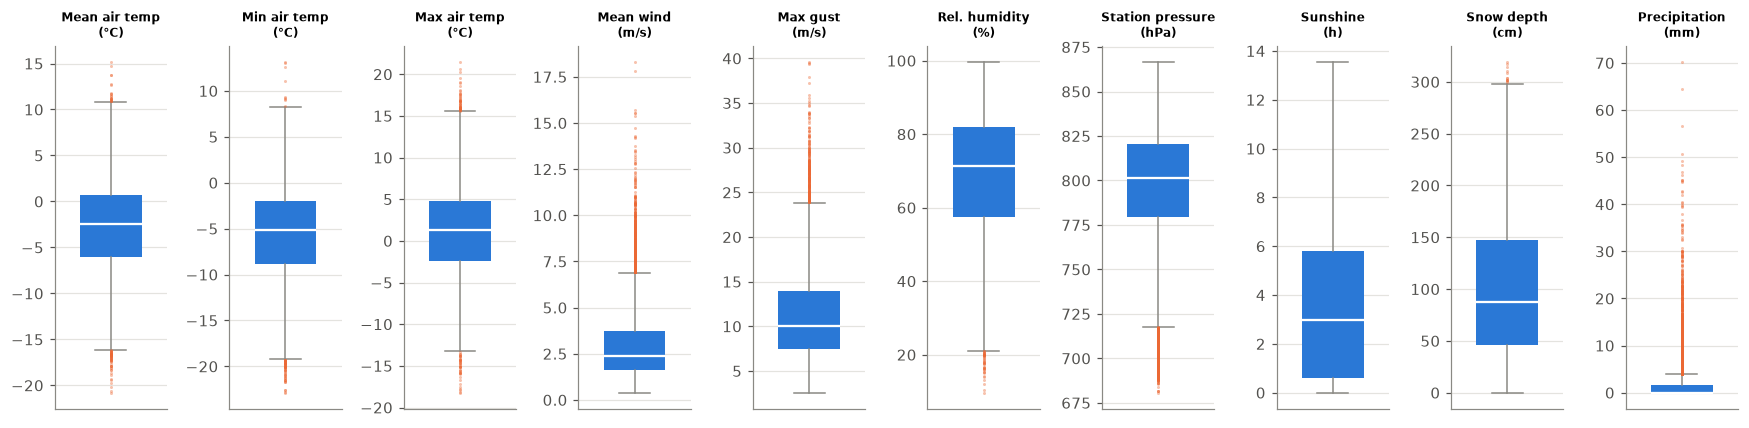

In [10]:
fig, axes = plt.subplots(1, 10, figsize=(16, 4))
for ax, (col, label) in zip(axes, NUM.items()):
    ax.boxplot(data[col].dropna(), widths=0.55, patch_artist=True,
               boxprops={"facecolor": BLUE, "edgecolor": "none"},
               medianprops={"color": "white", "linewidth": 1.5},
               whiskerprops={"color": GREY}, capprops={"color": GREY},
               flierprops={"marker": "o", "markersize": 2, "markerfacecolor": ORANGE, "markeredgecolor": "none", "alpha": 0.4})
    ax.set_title(label.replace(" (", "\n("), fontsize=8); ax.set_xticks([])
plt.tight_layout()

- many points beyond the whiskers for precipitation, wind speed and gusts (long right tails),
- many low outliers for humidity and pressure

### 2.5 Violin plots
A violin plot shows the (mirrored) density, so it adds the shape that the boxplot hides. We compare snow depth and pressure across the 9 stations, because the multimodal histograms suggested a station effect.

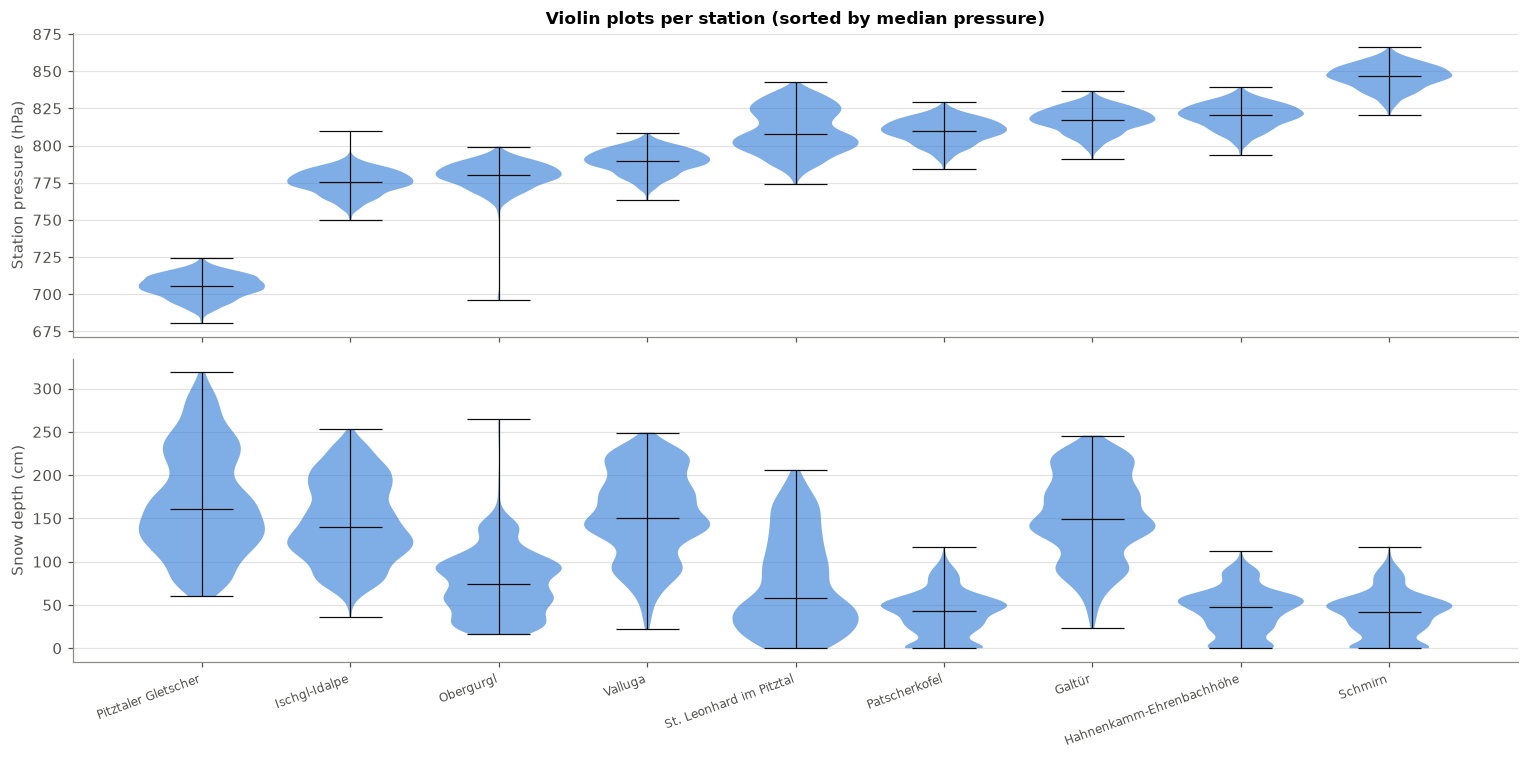

In [11]:
stations = data.groupby("station_name")["pressure_mean"].median().sort_values().index
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, col in zip(axes, ["pressure_mean", "snow_depth_cm"]):
    groups = [data.loc[data["station_name"] == s, col].dropna() for s in stations]
    vp = ax.violinplot(groups, showmedians=True, widths=0.85)
    for b in vp["bodies"]:
        b.set_facecolor(BLUE); b.set_edgecolor("none"); b.set_alpha(0.6)
    for k in ["cmedians", "cmins", "cmaxes", "cbars"]:
        vp[k].set_color("#0b0b0b"); vp[k].set_linewidth(0.8)
    ax.set_ylabel(NUM[col]); ax.grid(axis="x", visible=False)
axes[1].set_xticks(range(1, len(stations) + 1), stations, rotation=20, ha="right", fontsize=8)
axes[0].set_title("Violin plots per station (sorted by median pressure)")
plt.tight_layout()

* **Pressure:** each station has its own narrow distribution. The left-skewed pressure distribution is just the mix of these 9 stations.
* **Snow depth:** the stations differ strongly in level and shape. Some distributions are bimodal because of many 0-cm days at the start and end of the season plus a winter peak.


**Consequences:**
- For modelling, we should use pressure (and possibly snow depth) **relative to the station** (for standardization)

### 2.6 Normal Q–Q plots

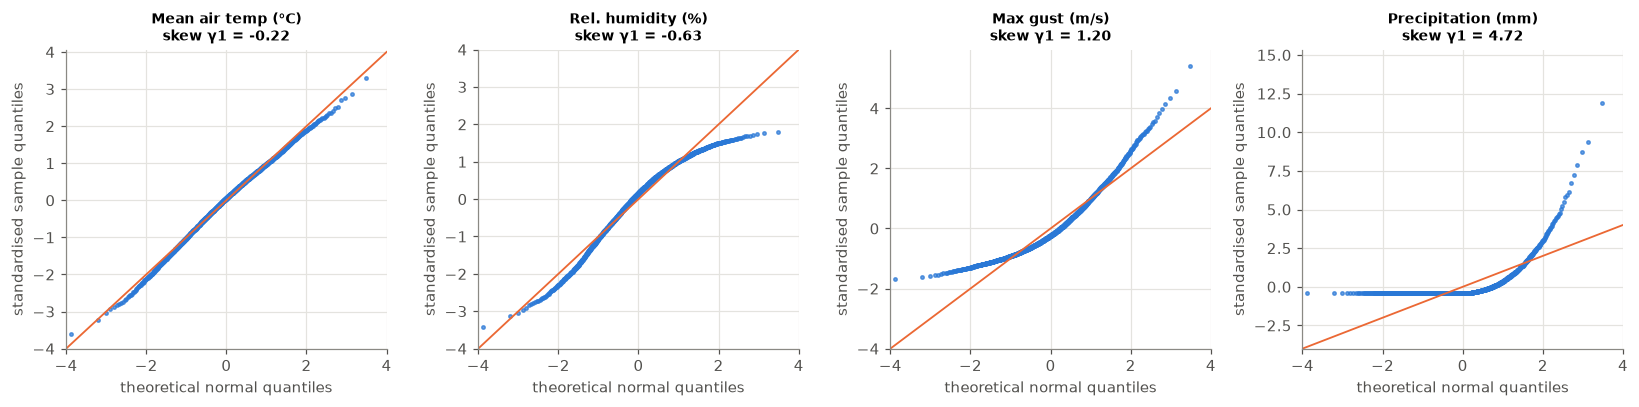

In [12]:
def moment_shape(x):   # moment skewness γ1 and kurtosis κ
    x = x.dropna()
    d = x - x.mean()
    m2, m3, m4 = (d**2).mean(), (d**3).mean(), (d**4).mean()
    return m3 / m2**1.5, m4 / m2**2

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, col in zip(axes, ["air_temp_mean", "rel_humidity_mean", "wind_gust_max", "precip_sum_mm"]):
    x = np.sort(data[col].dropna().values)
    n = len(x)
    p = (np.arange(1, n + 1) - 0.5) / n
    theo = np.array([NormalDist().inv_cdf(q) for q in p])
    z = (x - x.mean()) / x.std(ddof=1)
    step = max(1, n // 1500)
    ax.scatter(theo[::step], z[::step], s=5, color=BLUE, alpha=0.7)
    ax.plot([-4, 4], [-4, 4], color=ORANGE, lw=1.2)
    ax.set_xlim(-4, 4); ax.set_ylim(-4, max(4, z.max() + 0.5))
    ax.set_title(f"{NUM[col]}\nskew γ1 = {moment_shape(data[col])[0]:.2f}", fontsize=9)
    ax.set_xlabel("theoretical normal quantiles"); ax.set_ylabel("standardised sample quantiles")
plt.tight_layout()

* **Mean air temperature:** slight deviations in the tails: approximately normal.
* **Humidity** curves below the line at the left end.
* **Max gust** curves upwards at the right end.
* **Precipitation** is far from normal: a flat segment at the bottom and a steep upward curve at the top.

**Consequences:** methods that assume normally distributed inputs or errors should not be applied to precipitation, wind or sunshine without transformation. Temperatures can be used as they are.

### Summary of the univariate analysis
| Variable group | Shape | Consequence |
|---|---|---|
| Danger level | ordinal, imbalanced (51% level 2, 4% level 4, no level 5) | macro-F1/per-class metrics, majority baseline, class weights |
| Temperatures | ≈ normal, few outliers | use as is |
| Precipitation, wind, gusts, sunshine | right-skewed, heavy tails, many zeros (precip/sun) | log transformation / robust scaling for linear models, keep outliers |
| Humidity | left-skewed, bounded at 100% | robust statistics |
| Pressure, snow depth | multimodal because of different stations | normalise per station / add region feature |

## 3. Multivariate non-graphical EDA

### 3.1 Cross-tabulation

In [13]:
def crosstab_with_pct(row):
    counts = pd.crosstab(data[row], data["danger_max"], margins=True, margins_name="total")
    pct = pd.crosstab(data[row], data["danger_max"], normalize="index") * 100
    return counts, pct

counts, pct = crosstab_with_pct("station_name")
print("counts:"); print(counts.to_string())
print("\nrow percentages:"); pct.round(1)

counts:
danger_max                   1     2     3    4  total
station_name                                          
Galtür                     146   521   354   60   1081
Hahnenkamm-Ehrenbachhöhe   343   532   187   19   1081
Ischgl-Idalpe              137   551   346   47   1081
Obergurgl                  117   560   349   55   1081
Patscherkofel              130   569   346   36   1081
Pitztaler Gletscher        124   539   371   47   1081
Schmirn                    105   550   373   53   1081
St. Leonhard im Pitztal    127   576   342   36   1081
Valluga                    157   531   330   63   1081
total                     1386  4929  2998  416   9729

row percentages:


danger_max,1,2,3,4
station_name,,,,
Galtür,13.5,48.2,32.7,5.6
Hahnenkamm-Ehrenbachhöhe,31.7,49.2,17.3,1.8
Ischgl-Idalpe,12.7,51.0,32.0,4.3
Obergurgl,10.8,51.8,32.3,5.1
Patscherkofel,12.0,52.6,32.0,3.3
Pitztaler Gletscher,11.5,49.9,34.3,4.3
Schmirn,9.7,50.9,34.5,4.9
St. Leonhard im Pitztal,11.7,53.3,31.6,3.3
Valluga,14.5,49.1,30.5,5.8


In [14]:
for row in ["season", "month", "tendency"]:
    _, pct = crosstab_with_pct(row)
    if row == "month":
        pct = pct.reindex([11, 12, 1, 2, 3, 4, 5])
    print(f"--- danger level by {row} (row %)")
    print(pct.round(1).to_string(), "\n")

--- danger level by season (row %)
danger_max     1     2     3    4
season                           
2019/20     19.4  56.7  19.5  4.4
2020/21      2.7  40.8  50.1  6.4
2021/22     21.8  44.1  28.7  5.5
2022/23      7.5  51.8  37.9  2.8
2023/24      7.5  60.9  28.7  2.9
2024/25     23.9  59.0  15.9  1.2
2025/26     17.0  41.0  35.5  6.5 

--- danger level by month (row %)
danger_max     1     2     3    4
month                            
11          15.9  45.4  33.8  4.8
12          14.4  41.3  37.7  6.6
1           15.8  53.7  25.5  5.1
2           11.3  38.8  40.8  9.0
3           19.7  54.1  25.3  0.8
4           10.0  64.0  25.4  0.6
5            7.2  58.2  34.6  0.0 

--- danger level by tendency (row %)
danger_max     1     2     3     4
tendency                          
decreasing   1.1  36.8  51.8  10.3
increasing  20.5  50.0  26.7   2.9
steady      14.9  52.4  29.0   3.8 



In [15]:
# Previous day's level (known before the bulletin) vs. today's level: a cross-tab of two categorical variables
prev = data["prev_danger"]
trans = pd.crosstab(prev.rename("level yesterday"), data["danger_max"].rename("level today"), normalize="index") * 100
print(f"level unchanged from the previous day: {(prev == data['danger_max'])[prev.notna()].mean():.1%}")
trans.round(1)

level unchanged from the previous day: 79.2%


level today,1,2,3,4
level yesterday,,,,
1.0,79.1,19.0,1.3,0.6
2.0,6.1,82.9,10.5,0.6
3.0,0.0,19.6,75.9,4.5
4.0,0.0,0.0,41.6,58.4


* **Regions:** 8 of 9 regions have very similar distributions.
* **Seasons:** the share of level-4 days varies several-fold between winters (e.g. ~1% in 2024/25 vs. ~6.5% in 2025/26).
* **Months:** level 4 is most frequent in February (9%) and December (6.6%), and almost never occurs from March on (< 1%). In spring level 2 dominates (54–64%).
* **Yesterday's level:** about 79% of days keep the previous day's level.

**Consequences:** 
- region and month/season are useful categorical features. 
- The model must beat a **persistence baseline** (predict yesterday's level, ~79% accuracy). 
- Train/test must be split **by season**, because neighbouring days are almost identical.



## 4. Multivariate graphical EDA

### 4.1 Univariate graph per category: grouped boxplots

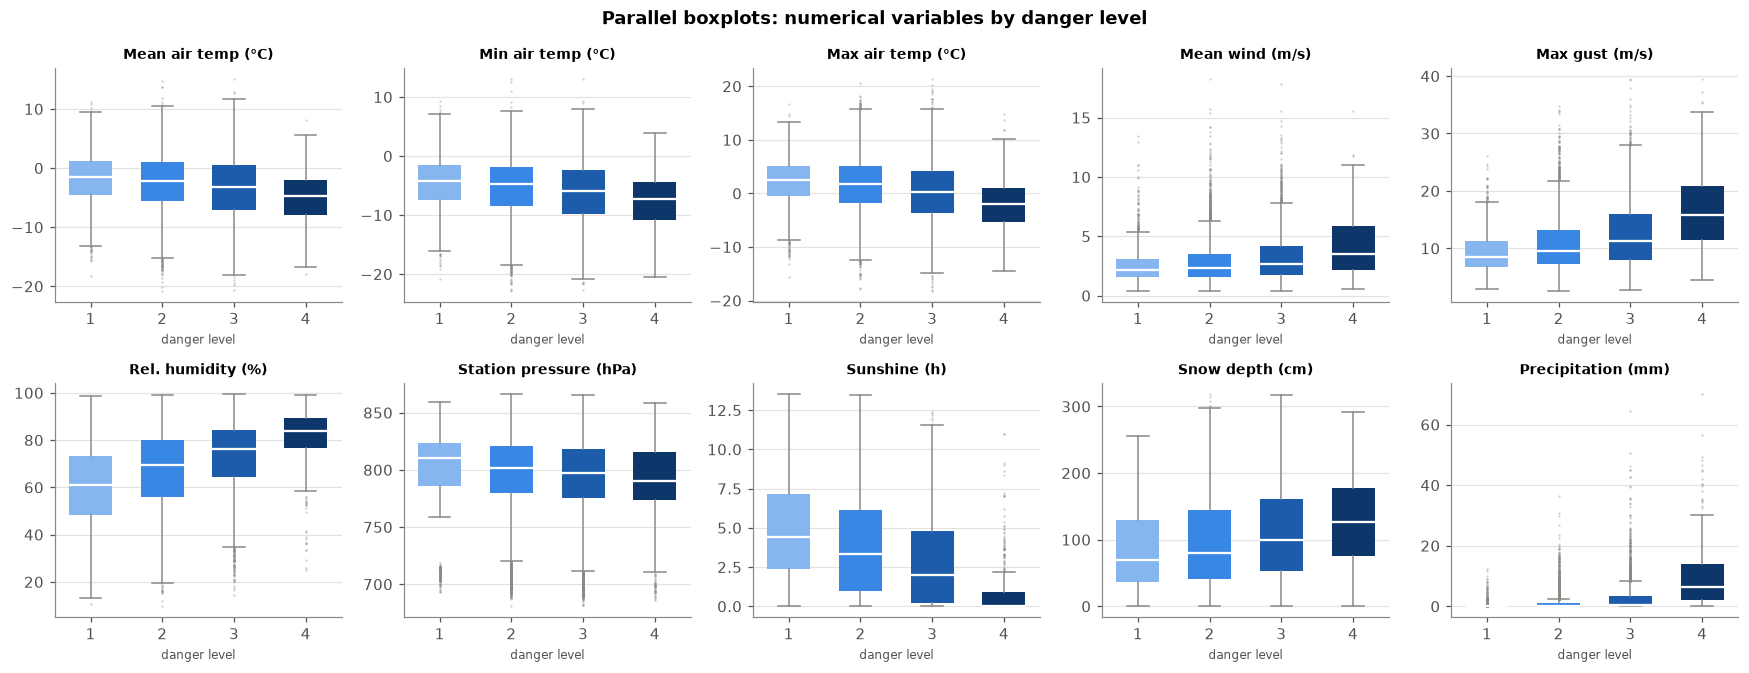

In [16]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6.2))
for ax, (col, label) in zip(axes.flat, NUM.items()):
    groups = [data.loc[data["danger_max"] == l, col].dropna() for l in LEVELS]
    bp = ax.boxplot(groups, tick_labels=LEVELS, widths=0.6, patch_artist=True,
                    medianprops={"color": "white", "linewidth": 1.5},
                    whiskerprops={"color": GREY}, capprops={"color": GREY},
                    flierprops={"marker": "o", "markersize": 1.5, "markerfacecolor": GREY, "markeredgecolor": "none", "alpha": 0.4})
    for patch, l in zip(bp["boxes"], LEVELS):
        patch.set(facecolor=LEVEL_COLORS[l], edgecolor="none")
    ax.set_title(label, fontsize=9); ax.set_xlabel("danger level", fontsize=8)
    ax.grid(axis="x", visible=False)
fig.suptitle("Parallel boxplots: numerical variables by danger level", fontweight="bold")
plt.tight_layout()

* With increasing danger level, precipitation, gusts, humidity and snow depth shift **upwards**, while sunshine and temperature shift **downwards**.
* Neighbouring levels overlap strongly (especially 2 and 3), consistent with the weak-to-moderate correlations.
* The **spread** changes too: precipitation and gusts vary much more at levels 3–4, while humidity and sunshine vary less at level 4.

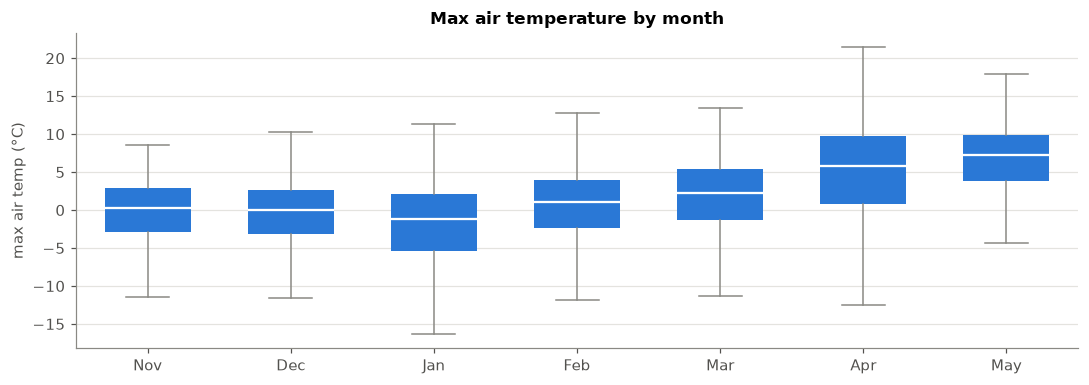

In [17]:
months = [11, 12, 1, 2, 3, 4, 5]
fig, ax = plt.subplots(figsize=(10, 3.6))
groups = [data.loc[data["month"] == m, "air_temp_max"] for m in months]
bp = ax.boxplot(groups, tick_labels=["Nov", "Dec", "Jan", "Feb", "Mar", "Apr", "May"], widths=0.6, patch_artist=True,
                showfliers=False, medianprops={"color": "white", "linewidth": 1.5},
                whiskerprops={"color": GREY}, capprops={"color": GREY})
for patch in bp["boxes"]:
    patch.set(facecolor=BLUE, edgecolor="none")
ax.set_ylabel("max air temp (°C)"); ax.set_title("Max air temperature by month"); ax.grid(axis="x", visible=False)
plt.tight_layout()

- Temperature depends strongly on the month (cold mid-winter, warm spring).

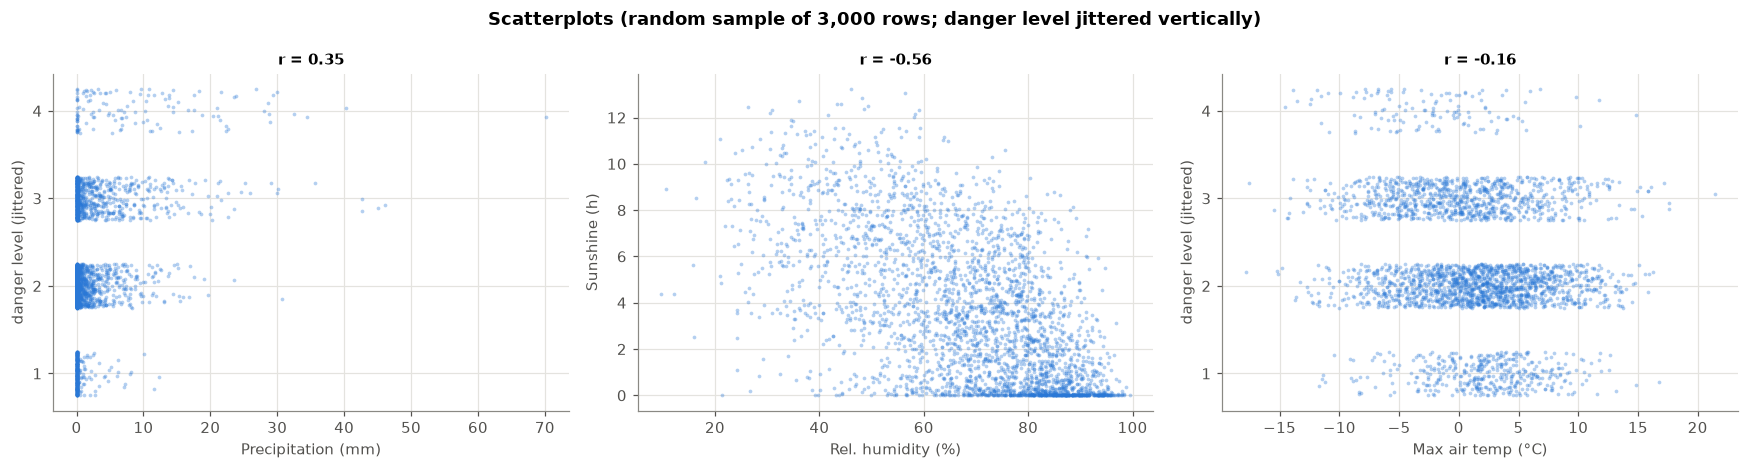

In [18]:
rng = np.random.default_rng(0)
sub = data.sample(3000, random_state=0)
jit = rng.uniform(-0.25, 0.25, len(sub))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
pairs_to_plot = [("precip_sum_mm", "danger_max"), ("rel_humidity_mean", "sunshine_sum"), ("air_temp_max", "danger_max")]
for ax, (xc, yc) in zip(axes, pairs_to_plot):
    yy = sub[yc] + (jit if yc == "danger_max" else 0)
    ax.scatter(sub[xc], yy, s=6, alpha=0.35, color=BLUE, lw=0)
    ax.set_xlabel(NUM.get(xc, xc)); ax.set_ylabel(NUM.get(yc, "danger level (jittered)"))
    ax.set_title(f"r = {data[xc].corr(data[yc]):.2f}", fontsize=10)
    if yc == "danger_max":
        ax.set_yticks(LEVELS)
fig.suptitle("Scatterplots (random sample of 3,000 rows; danger level jittered vertically)", fontweight="bold")
plt.tight_layout()

* **Precipitation vs. danger:** dry days occur at every level, but days with a lot of precipitation are almost never level 1. The relationship is not linear: it looks more like "heavy precipitation -> high level", while low precipitation says little.
* **Humidity vs. sunshine:** a clear negative, slightly curved relationship (humid days are overcast).
* **Max temperature vs. danger:** almost no visible linear trend.

,Galtür,Hahnenkamm-Ehrenbachhöhe,Ischgl-Idalpe,Obergurgl,Patscherkofel,Pitztaler Gletscher,Schmirn,St. Leonhard im Pitztal,Valluga
"r(pressure, snow depth) within station",0.08,0.01,0.06,-0.04,0.01,0.03,0.04,0.72,0.07


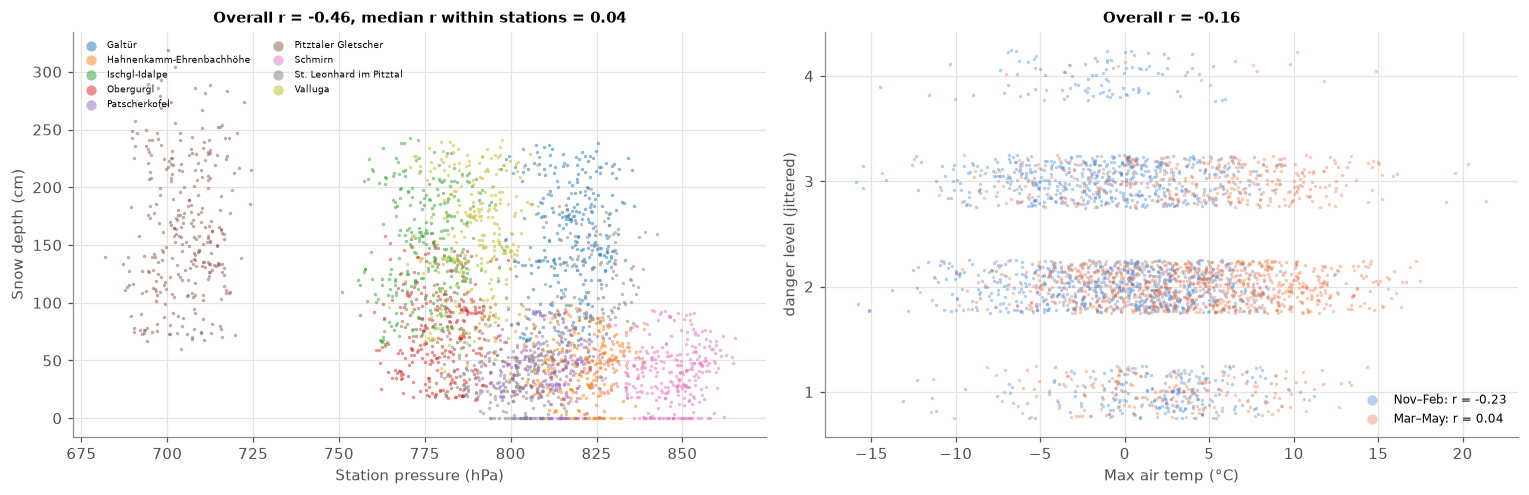

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

# (a) snow depth vs. pressure: overall vs. within each station
ax = axes[0]
cmap = plt.get_cmap("tab10")
within = {}
for i, (st, g) in enumerate(data.groupby("station_name")):
    s = g.sample(min(len(g), 300), random_state=0)
    ax.scatter(s["pressure_mean"], s["snow_depth_cm"], s=5, alpha=0.5, color=cmap(i), lw=0, label=st)
    within[st] = g["pressure_mean"].corr(g["snow_depth_cm"])
ax.set_xlabel(NUM["pressure_mean"]); ax.set_ylabel(NUM["snow_depth_cm"])
ax.set_title(f"Overall r = {data['pressure_mean'].corr(data['snow_depth_cm']):.2f}, "
             f"median r within stations = {np.median(list(within.values())):.2f}", fontsize=10)
ax.legend(fontsize=6, frameon=False, markerscale=3, ncol=2, loc="upper left")

# (b) temperature vs. danger level: within early winter vs. spring
ax = axes[1]
spring = data["spring"]
for mask, color, name in [(~spring, BLUE, "Nov–Feb"), (spring, ORANGE, "Mar–May")]:
    g = data[mask]
    s = g.sample(1500, random_state=0)
    ax.scatter(s["air_temp_max"], s["danger_max"] + rng.uniform(-0.25, 0.25, len(s)), s=5, alpha=0.35, color=color, lw=0,
               label=f"{name}: r = {g['air_temp_max'].corr(g['danger_max']):.2f}")
ax.set_yticks(LEVELS); ax.set_xlabel(NUM["air_temp_max"]); ax.set_ylabel("danger level (jittered)")
ax.set_title(f"Overall r = {data['air_temp_max'].corr(data['danger_max']):.2f}", fontsize=10)
ax.legend(fontsize=8, frameon=False, markerscale=3)
plt.tight_layout()

pd.Series(within, name="r(pressure, snow depth) within station").round(2).to_frame().T

**Pressure vs. snow depth:**
- overall r = −0.46, but within 8 of 9 stations r ≈ 0.
- higher stations have both lower pressure and more snow, so station elevation is a **confounder**.

**Temperature vs. danger:**
- in mid-winter (Nov–Feb) warmer days have lower danger (r ≈ −0.23, since cold days bring storms and new snow); in spring (Mar–May) the relationship disappears (r ≈ 0.04, as warmth also causes wet-snow danger).

**Consequences:** the model needs station/region and month as features. Models that learn interactions (e.g. trees) fit better than a single linear temperature effect

### 4.3 Scatterplot matrix

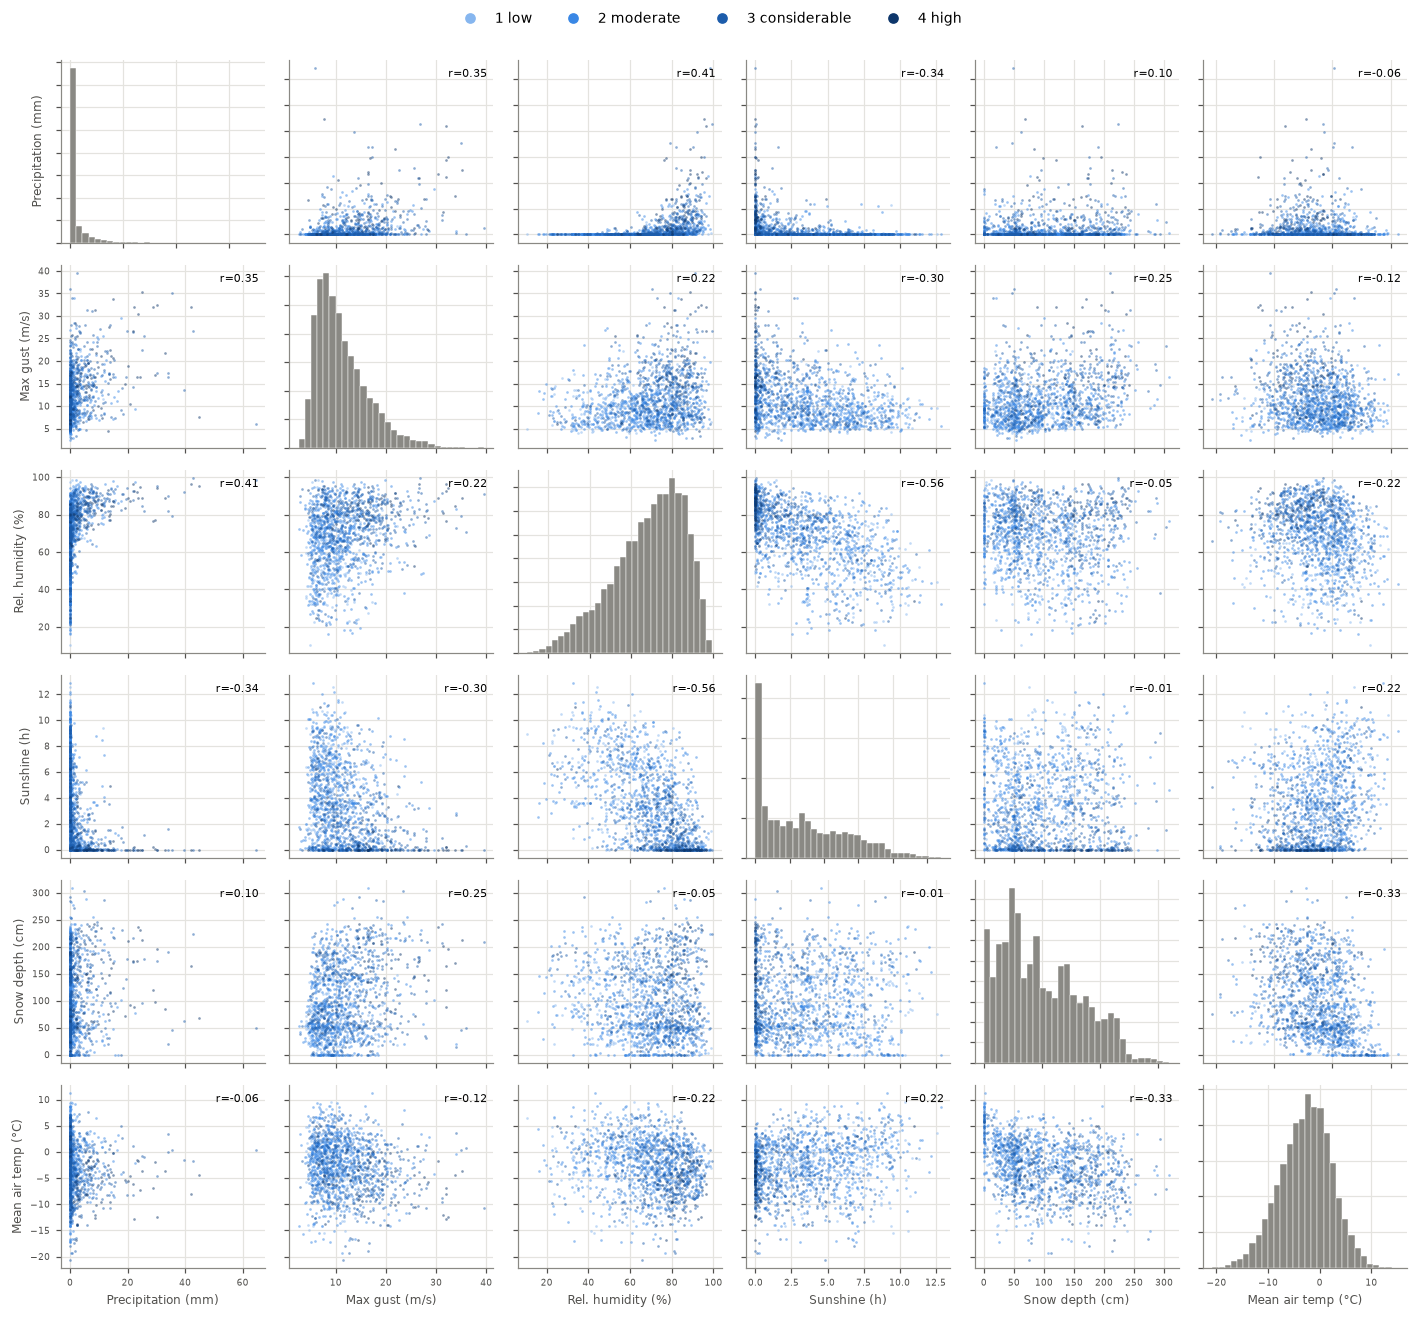

In [20]:
SPM = ["precip_sum_mm", "wind_gust_max", "rel_humidity_mean", "sunshine_sum", "snow_depth_cm", "air_temp_mean"]
s = data.sample(1500, random_state=1)
k = len(SPM)
fig, axes = plt.subplots(k, k, figsize=(13, 12))
for i, yc in enumerate(SPM):
    for j, xc in enumerate(SPM):
        ax = axes[i, j]
        if i == j:
            ax.hist(data[xc], bins=30, color=GREY, edgecolor="white", linewidth=0.3)
        else:
            for l in LEVELS:
                m = s["danger_max"] == l
                ax.scatter(s.loc[m, xc], s.loc[m, yc], s=3, alpha=0.5, color=LEVEL_COLORS[l], lw=0)
            ax.text(0.97, 0.95, f"r={data[xc].corr(data[yc]):.2f}", transform=ax.transAxes, ha="right", va="top", fontsize=7)
        ax.tick_params(labelsize=6)
        if i == k - 1: ax.set_xlabel(NUM[xc], fontsize=8)
        else: ax.set_xticklabels([])
        if j == 0: ax.set_ylabel(NUM[yc], fontsize=8)
        if j > 0 or i == j: ax.set_yticklabels([])   # diagonal y-axis = counts, not the variable
handles = [plt.Line2D([], [], marker="o", ls="", color=LEVEL_COLORS[l], label=LEVEL_NAMES[l]) for l in LEVELS]
fig.legend(handles=handles, loc="upper center", ncol=4, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.97))

* Several relationships are clearly **nonlinear** (precipitation vs. humidity: precipitation is only > 0 above a humidity threshold), which r does not capture.
* The levels still overlap in every 2-D view, so a model needs several variables together.

### 4.4 Correlation heatmap


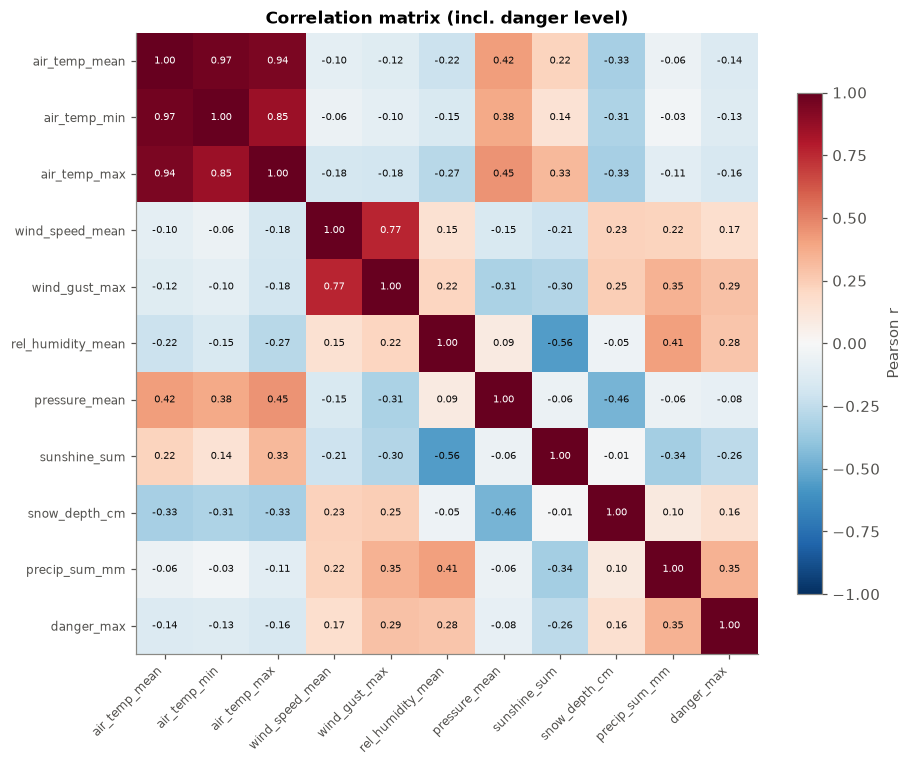

In [21]:
COLS = list(NUM) + ["danger_max"]
corr = data[COLS].corr()          # Pearson

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(corr)), corr.index, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5, color="white" if abs(v) > 0.6 else "#0b0b0b")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Correlation matrix (incl. danger level)")
plt.tight_layout()

Two blocks stand out:
- **temperature block** (mean/min/max, very strongly positive) and
- **storm block** (precipitation, humidity, gusts, wind positive with each other and negative with sunshine).
- The danger level (last row) belongs to the storm block.

**Consequences:**
- for linear models keep only one variable per highly correlated group (e.g. `air_temp_mean`, `wind_gust_max`), otherwise the coefficients are unstable.
- because no single feature is strongly related to the target, the model has to combine several weak signals.

### 4.5 Engineered features

danger_max,1,2,3,4
log_precip_3d,0.00,0.81,1.70,2.87
precip_7d,1.64,6.21,13.80,26.67
snow_change_3d,-1.94,-1.88,-0.62,4.53
snow_change_14d,-5.80,-2.29,7.44,19.26
temp_mean_14d,-1.82,-2.61,-3.76,-4.89
pressure_anom,3.36,1.32,-1.66,-4.41
snow_depth_z,-0.26,-0.13,0.20,0.59


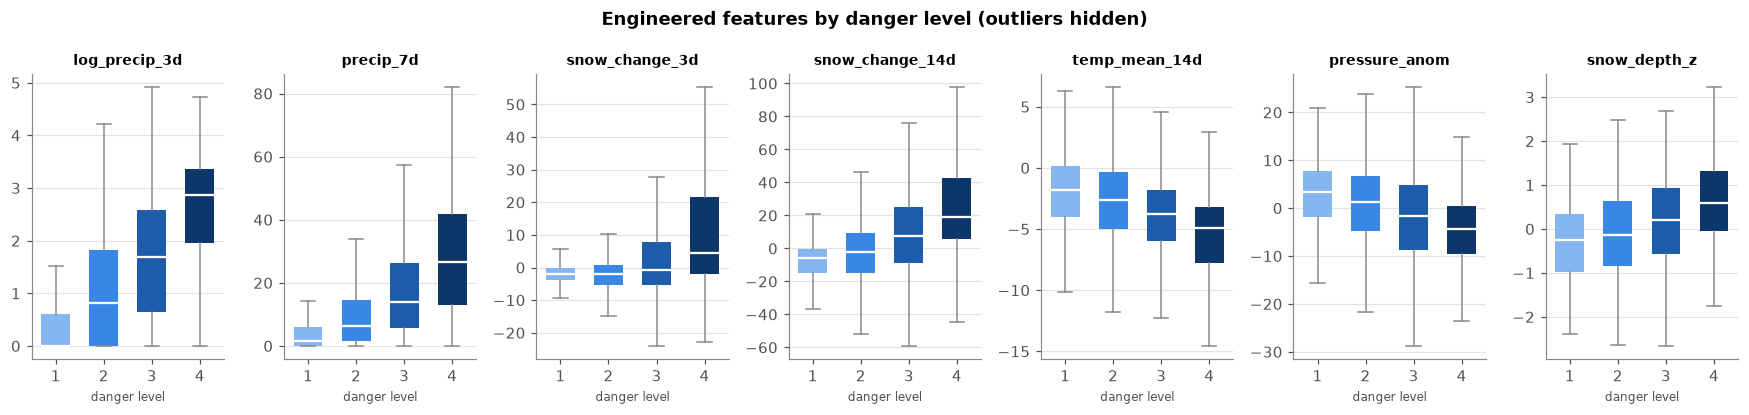

In [22]:
show = ["log_precip_3d", "precip_7d", "snow_change_3d", "snow_change_14d", "temp_mean_14d", "pressure_anom", "snow_depth_z"]
fig, axes = plt.subplots(1, len(show), figsize=(16, 3.8))
for ax, col in zip(axes, show):
    groups = [data.loc[data["danger_max"] == l, col].dropna() for l in LEVELS]
    bp = ax.boxplot(groups, tick_labels=LEVELS, widths=0.6, patch_artist=True, showfliers=False,
                    medianprops={"color": "white", "linewidth": 1.5},
                    whiskerprops={"color": GREY}, capprops={"color": GREY})
    for patch, l in zip(bp["boxes"], LEVELS):
        patch.set(facecolor=LEVEL_COLORS[l], edgecolor="none")
    ax.set_title(col, fontsize=9); ax.set_xlabel("danger level", fontsize=8); ax.grid(axis="x", visible=False)
fig.suptitle("Engineered features by danger level (outliers hidden)", fontweight="bold")
plt.tight_layout()

data.groupby("danger_max")[show].median().T

For all engineered features, the median increases (or decreases) steadily from level 1 to level 4. The levels are more clearly separated than with the raw daily variables in 4.1, most notably for `log_precip_3d` and `snow_change_14d`, which supports using multi-day aggregates. However, levels 2 and 3 still overlap considerably.

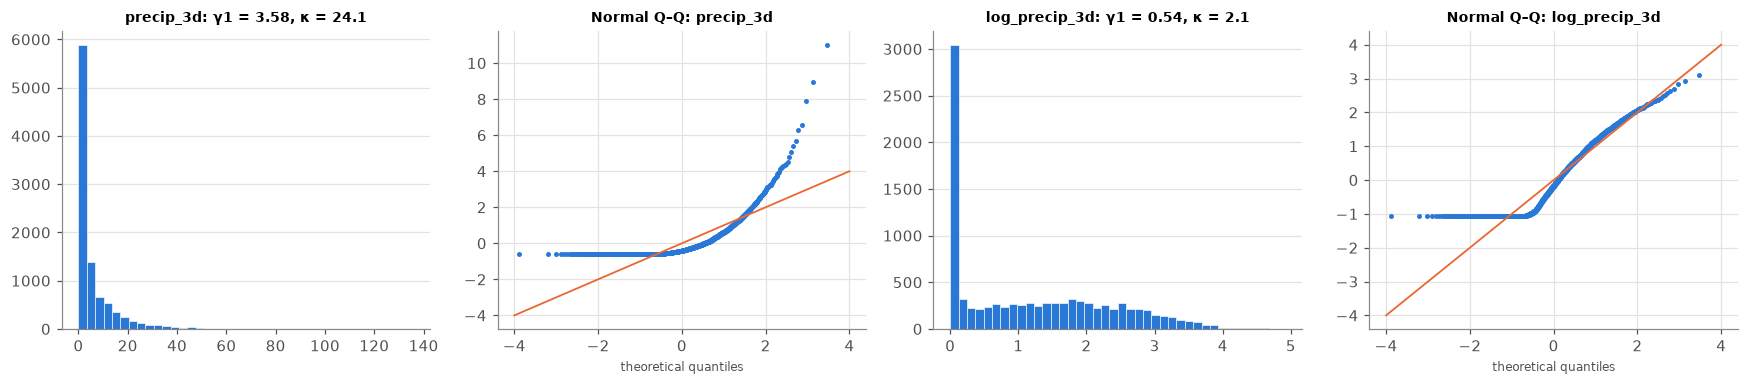

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for k, col in enumerate(["precip_3d", "log_precip_3d"]):
    x = data[col].dropna()
    axes[2 * k].hist(x, bins=40, color=BLUE, edgecolor="white", linewidth=0.4)
    axes[2 * k].set_title(f"{col}: γ1 = {moment_shape(x)[0]:.2f}, κ = {moment_shape(x)[1]:.1f}", fontsize=9)
    axes[2 * k].grid(axis="x", visible=False)
    xs = np.sort(x.values); n = len(xs)
    theo = np.array([NormalDist().inv_cdf(q) for q in (np.arange(1, n + 1) - 0.5) / n])
    z = (xs - xs.mean()) / xs.std(ddof=1)
    axes[2 * k + 1].scatter(theo[::6], z[::6], s=5, color=BLUE)
    axes[2 * k + 1].plot([-4, 4], [-4, 4], color=ORANGE, lw=1.2)
    axes[2 * k + 1].set_title(f"Normal Q–Q: {col}", fontsize=9)
    axes[2 * k + 1].set_xlabel("theoretical quantiles", fontsize=8)
plt.tight_layout()

The log transformation strongly reduces the skewness and kurtosis of the 3-day precipitation and removes the long right tail. The distribution is still not normal, since the many dry days form a block at 0 in the Q–Q plot, but it is considerably better suited for linear models than the raw values.

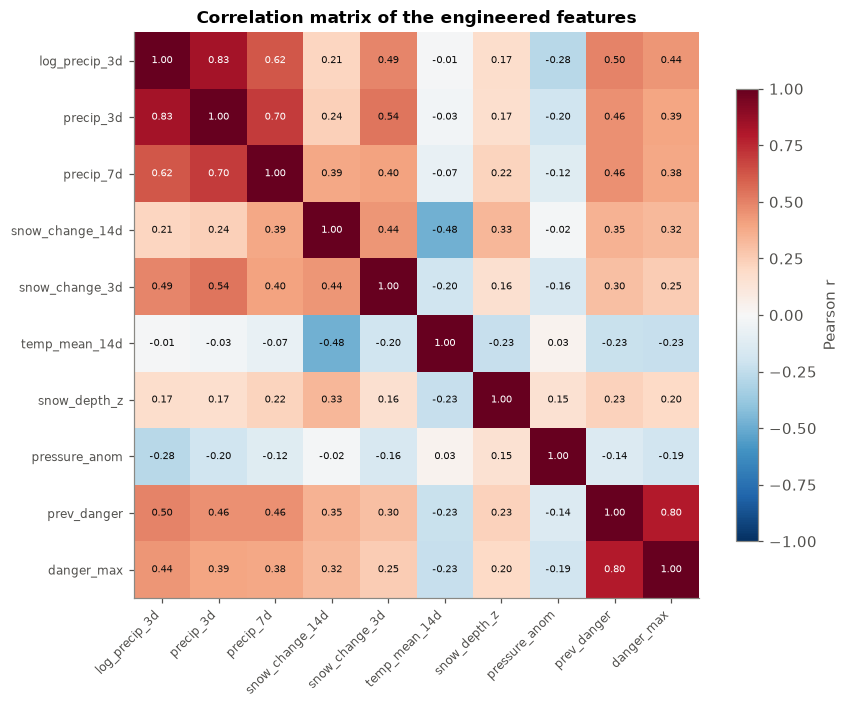

In [24]:
cols = list(ENG_NUM) + ["prev_danger", "danger_max"]
c = data[cols].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(c)), c.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(c)), c.index, fontsize=8)
for i in range(len(c)):
    for j in range(len(c)):
        v = c.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5, color="white" if abs(v) > 0.6 else "#0b0b0b")
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Correlation matrix of the engineered features")
plt.tight_layout()

* `precip_3d`, `precip_7d` and `log_precip_3d` are strongly correlated because they cover overlapping days. A linear model should keep only one or two of them, while tree-based models can use all three.
* `snow_change_3d` correlates strongly with `precip_3d` (r ≈ 0.54), as both capture recent fresh snow. `snow_change_14d` and `temp_mean_14d` are moderately negatively correlated (r ≈ −0.48), because warm periods cause the snowpack to settle.
* `snow_depth_z`, `pressure_anom` and `temp_mean_14d` correlate only weakly with the precipitation features and therefore contribute **additional** information.

**Consequences:** the modelling notebook will combine the raw weather variables with these engineered features in two feature sets: **A** (weather only: raw + engineered) and **B** (A + `prev_danger`), to separate the weather signal from the persistence of the previous day's danger level.